# 🪐 Asteroid Hazard Prediction Using Machine Learning
**Author:** [Shivam Gopal]  
**Roll Number:** [23035010167]  

---
### 1. Introduction
**This project aims to predict whether a Near-Earth Object (NEO) asteroid is potentially hazard**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **=== 1. Import necessary libraries ===**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

## **Set visual style for clean, professional plots**


In [ ]:
# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
file_path = '/content/drive/MyDrive/Asteroid Hazard Prediction/asteroids_data.csv'

try:
    df = pd.read_csv(file_path)
    print(f"Dataset loaded successfully! Shape: {df.shape}")
except FileNotFoundError:
    print(f"Error: The file at '{file_path}' was not found. Please verify your drive path.")
    exit()

Dataset loaded successfully! Shape: (2000, 39)


# **=== 2. Data Preprocessing & Cleaning ===**

In [ ]:
# Display first 5 rows
display(df.head())

,id,neo_id,name,short_name,designation,nasa_url,magnitude,potentially_hazardous,close_approach_data,sentry,...,perihelion_argument,aphelion_distance,perihelion_time,mean_anomaly,mean_motion,equinox,orbit_class_type,orbit_class_desc,orbit_class_range,sentry_data
0,2001620,2001620,1620 Geographos (1951 RA),Geographos,1620,https://ssd.jpl.nasa.gov/tools/sbdb_lookup.htm...,15.26,True,"[{'close_approach_date': '1901-08-23', 'close_...",False,...,277.018390,1.663750,2.461208e+06,212.920449,0.708833,J2000,APO,Near-Earth asteroid orbits which cross the Ear...,a (semi-major axis) > 1.0 AU; q (perihelion) <...,NaN
1,2001863,2001863,1863 Antinous (1948 EA),Antinous,1863,https://ssd.jpl.nasa.gov/tools/sbdb_lookup.htm...,15.35,False,"[{'close_approach_date': '1907-10-11', 'close_...",False,...,269.074546,3.630348,2.461243e+06,289.564484,0.290073,J2000,APO,Near-Earth asteroid orbits which cross the Ear...,a (semi-major axis) > 1.0 AU; q (perihelion) <...,NaN
2,2001915,2001915,1915 Quetzalcoatl (1953 EA),Quetzalcoatl,1915,https://ssd.jpl.nasa.gov/tools/sbdb_lookup.htm...,18.38,False,"[{'close_approach_date': '1906-03-06', 'close_...",False,...,347.755255,3.995972,2.460911e+06,21.616448,0.242780,J2000,AMO,Near-Earth asteroid orbits similar to that of ...,1.017 AU < q (perihelion) < 1.3 AU,NaN
3,2001917,2001917,1917 Cuyo (1968 AA),Cuyo,1917,https://ssd.jpl.nasa.gov/tools/sbdb_lookup.htm...,14.38,False,"[{'close_approach_date': '1926-09-28', 'close_...",False,...,194.552572,3.235478,2.460489e+06,160.089498,0.312848,J2000,AMO,Near-Earth asteroid orbits similar to that of ...,1.017 AU < q (perihelion) < 1.3 AU,NaN
4,2002063,2002063,2063 Bacchus (1977 HB),Bacchus,2063,https://ssd.jpl.nasa.gov/tools/sbdb_lookup.htm...,17.21,False,"[{'close_approach_date': '1903-03-06', 'close_...",False,...,55.350732,1.454683,2.461143e+06,234.787011,0.880596,J2000,APO,Near-Earth asteroid orbits which cross the Ear...,a (semi-major axis) > 1.0 AU; q (perihelion) <...,NaN


In [ ]:
# Drop non-predictive or redundant columns
columns_to_drop = [
    'id', 'neo_id', 'name', 'short_name', 'designation', 'nasa_url',
    'api_url', 'close_approach_data', 'sentry_data', 'sentry',
    'orbit_determination_date', 'first_observation_date', 'last_observation_date',
    'equinox', 'orbit_class_type', 'orbit_class_desc', 'orbit_class_range'
]
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

In [ ]:
# Convert target column to integer if boolean
target_col = 'potentially_hazardous'
if target_col in df.columns and df[target_col].dtype == bool:
    df[target_col] = df[target_col].astype(int)

In [ ]:
# Drop rows with missing values if any remain
df = df.dropna()

print(f"\nDataset shape after cleaning: {df.shape}")
print("\nClass distribution of target variable:")
print(df[target_col].value_counts())


Dataset shape after cleaning: (2000, 22)

Class distribution of target variable:
potentially_hazardous
0    1467
1     533
Name: count, dtype: int64


#   **=== 3. Exploratory Data Analysis (EDA) ===**

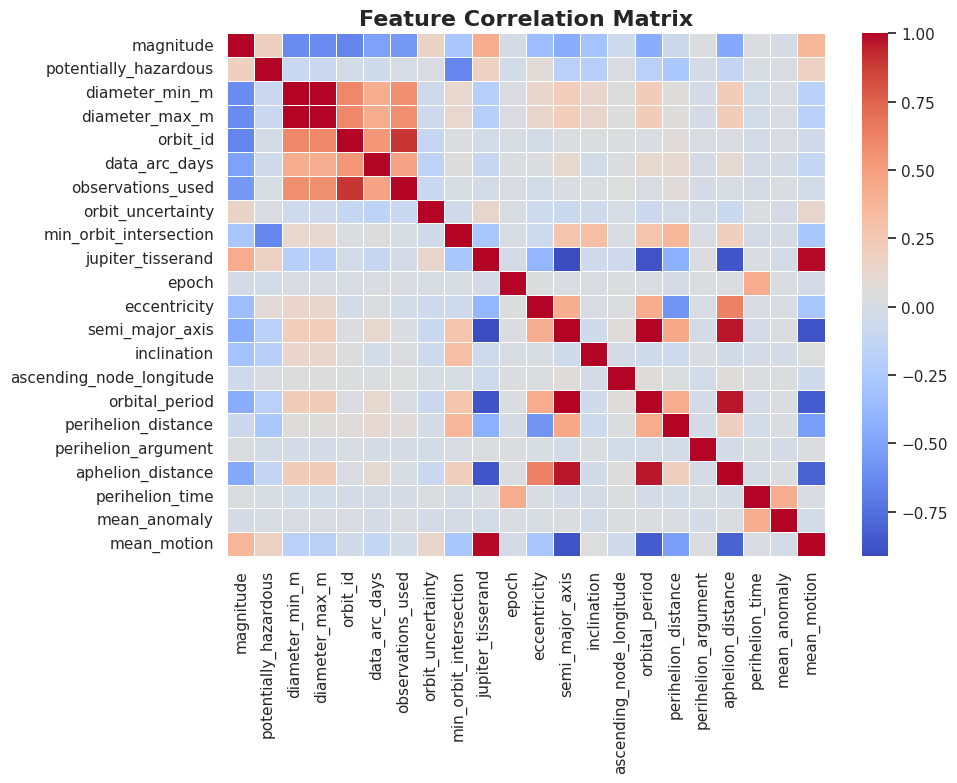

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_df.corr()

sns.heatmap(correlation_matrix, cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title("Feature Correlation Matrix", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300)
plt.show()

# **=== 4. Machine Learning Model Training & Evaluation===**

In [ ]:
# Define Features (X) and Target (y)
X = df.drop(columns=[target_col])
y = df[target_col]

In [ ]:
# Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Model Training
model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Predictions & Evaluation
y_pred = model.predict(X_test_scaled)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.9975

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       293
           1       1.00      0.99      1.00       107

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



Logistic Regression Accuracy: 0.9925
Random Forest Accuracy: 0.9975
Gradient Boosting Accuracy: 0.9975


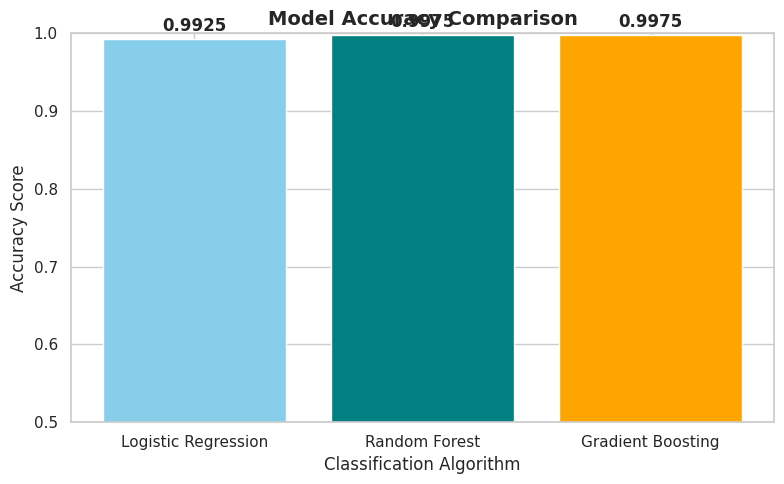

In [ ]:
# Initialize models
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": rf_model,
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

model_accuracies = {}

for name, clf in models.items():
    # Train if not already fitted
    if name != "Random Forest":
        clf.fit(X_train_scaled, y_train)

    y_pred_model = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_model)
    model_accuracies[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# Plot Model Comparison Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['skyblue', 'teal', 'orange'])
plt.ylim(0.5, 1.0)
plt.title("Model Accuracy Comparison", fontsize=14, fontweight='bold')
plt.ylabel("Accuracy Score")
plt.xlabel("Classification Algorithm")
for idx, val in enumerate(model_accuracies.values()):
    plt.text(idx, val + 0.01, f"{val:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

#  **=== 5. Confusion Matrix Heatmap ===**

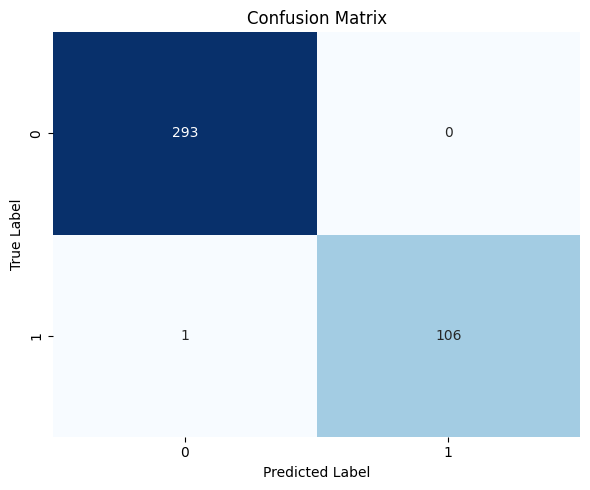

In [ ]:
# Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()


In [ ]:
def predict_asteroid_hazard(sample_data_dict):
    """
    Takes a dictionary of feature values, scales them using the fitted scaler,
    and returns the prediction.
    """
    # Convert input dict to DataFrame matching the training columns structure
    sample_df = pd.DataFrame([sample_data_dict])

    # Ensure columns match training data order
    sample_df = sample_df[X.columns]

    # Scale features
    sample_scaled = scaler.transform(sample_df)

    # Predict using Random Forest model
    prediction = rf_model.predict(sample_scaled)[0]
    probability = rf_model.predict_proba(sample_scaled)[0][1]

    result = "⚠️ POTENTIALLY HAZARDOUS ASTEROID" if prediction == 1 else "✅ Safe / Non-Hazardous Asteroid"
    print(f"Prediction Result: {result}")
    print(f"Hazard Probability: {probability * 100:.2f}%")

# Example test using the first row of your test set as a sample test case
sample_input = X_test.iloc[0].to_dict()
print("Testing with a sample from the test dataset:")
predict_asteroid_hazard(sample_input)

Testing with a sample from the test dataset:
Prediction Result: ✅ Safe / Non-Hazardous Asteroid
Hazard Probability: 0.00%


# **=== 6. Feature Importance Plot ===**

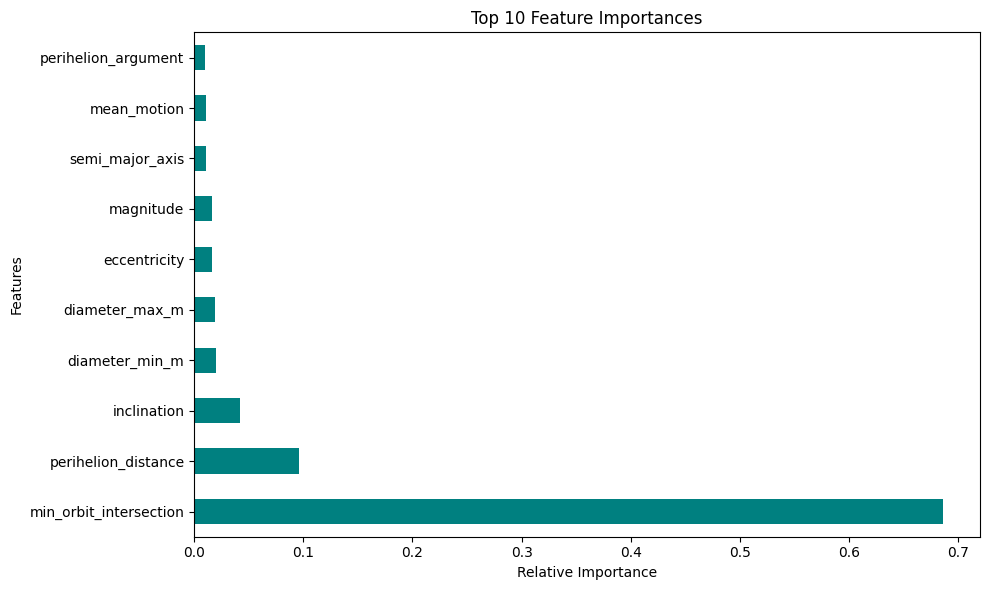

In [ ]:

# Feature Importance Plot
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title("Top 10 Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig("feature_importances.png")
plt.show()


In [ ]:
print("\nScript execution completed successfully. Charts saved as PNG files.")


Script execution completed successfully. Charts saved as PNG files.
